初期化

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

print(np.__version__)
print(matplotlib.__version__)

2.2.6
3.10.8


出力設定

In [2]:
# 画像出力先
out_path = "./img"

変数設定

In [4]:
fc = 424e3               # 424 kbps (1 bit = 1 cycle)
anchor_bits = 96         # ご指定のアンカー長
packet_cycle = anchor_bits 
window_size = 2**16      # 探索範囲を広めに設定

num_trials = 10000        # 試行回数
tags_range = np.arange(2, 257, 1)   # タグ数 N の範囲
d_range = np.arange(1, 50)         # 探索するデータ長 d の範囲

アンカー長 96 bit での最適化開始...
N= 2: Optimal d= 7, Total TP= 23040.0 bps
N= 3: Optimal d= 7, Total TP= 34291.7 bps
N= 4: Optimal d= 7, Total TP= 45424.9 bps
N= 5: Optimal d= 7, Total TP= 56301.4 bps
N= 6: Optimal d= 7, Total TP= 67240.6 bps
N= 7: Optimal d= 7, Total TP= 77542.0 bps
N= 8: Optimal d= 7, Total TP= 88201.3 bps
N= 9: Optimal d= 7, Total TP= 98237.9 bps
N=10: Optimal d= 7, Total TP=108402.3 bps
N=11: Optimal d= 7, Total TP=118272.8 bps
N=12: Optimal d= 7, Total TP=127952.7 bps
N=13: Optimal d= 7, Total TP=137534.0 bps
N=14: Optimal d= 7, Total TP=147083.9 bps
N=15: Optimal d= 7, Total TP=156593.1 bps
N=16: Optimal d= 7, Total TP=165348.4 bps
N=17: Optimal d= 7, Total TP=174370.9 bps
N=18: Optimal d= 7, Total TP=183158.7 bps
N=19: Optimal d= 7, Total TP=191779.3 bps
N=20: Optimal d= 7, Total TP=200669.3 bps
N=21: Optimal d= 7, Total TP=208831.0 bps
N=22: Optimal d= 6, Total TP=217210.9 bps
N=23: Optimal d= 7, Total TP=225325.2 bps
N=24: Optimal d= 6, Total TP=233483.4 bps
N=25: Opti

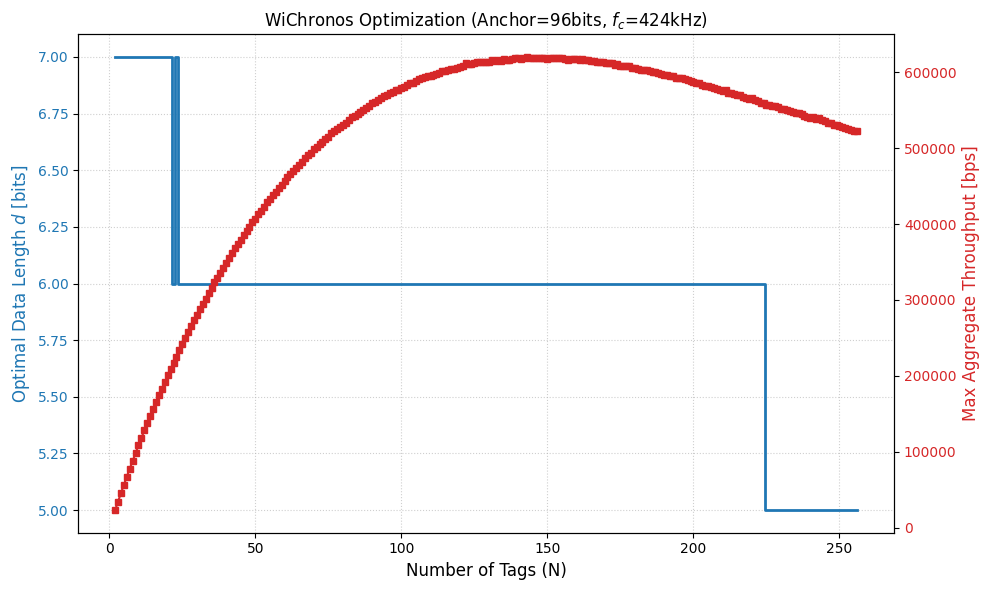

完了！ './imgPacPM_Optimization_96bit.pdf' を確認してください。


In [ ]:
# PacPMの最適化したbitとTag数の関係をグラフにするためのコード

# ============================================================
# 2. 高速衝突判定関数
# ============================================================
def get_avg_success_rate(num_tags, d_bits):
    success_counts = []
    for _ in range(num_trials):
        pre_starts = np.random.randint(0, window_size, size=num_tags)
        data_values = np.random.randint(0, 2**d_bits, size=num_tags)
        post_starts = pre_starts + anchor_bits + data_values
        
        all_pulses = np.concatenate([pre_starts, post_starts])
        tag_ids = np.concatenate([np.arange(num_tags), np.arange(num_tags)])
        
        s_idx = np.argsort(all_pulses)
        sorted_p = all_pulses[s_idx]
        sorted_tags = tag_ids[s_idx]
        
        diffs = np.diff(sorted_p)
        collision_mask = diffs < packet_cycle
        
        collided_indices = np.unique(np.concatenate([
            np.where(collision_mask)[0], 
            np.where(collision_mask)[0] + 1
        ]))
        
        failed_tag_ids = np.unique(sorted_tags[collided_indices])
        success_counts.append((num_tags - len(failed_tag_ids)) / num_tags)
        
    return np.mean(success_counts)

# ============================================================
# 3. 最適化ループ
# ============================================================
optimal_d_list = []
max_throughput_list = []

print(f"アンカー長 {anchor_bits} bit での最適化開始...")

for n in tags_range:
    best_d = 0
    best_tp = -1
    
    for d in d_range:
        p_success = get_avg_success_rate(n, d)
        
        # 1サイクルの平均時間 [s]
        t_cycle = (anchor_bits * 2 + (2**d - 1) / 2) / fc
        # 合計スループット [bps]
        total_tp = n * (p_success * d) / t_cycle
        
        if total_tp > best_tp:
            best_tp = total_tp
            best_d = d
            
    optimal_d_list.append(best_d)
    max_throughput_list.append(best_tp)
    print(f"N={n:2}: Optimal d={best_d:2}, Total TP={best_tp:8.1f} bps")

# ============================================================
# 4. プロットとPDF保存
# ============================================================
filename = f"{out_path}/PacPM_Optimization_96bit.pdf"
with PdfPages(filename) as pdf:
    fig, ax1 = plt.subplots(figsize=(10, 6))

    # 最適なデータ長 d のプロット (左軸)
    color1 = 'tab:blue'
    ax1.set_xlabel('Number of Tags (N)', fontsize=12)
    ax1.set_ylabel('Optimal Data Length $d$ [bits]', color=color1, fontsize=12)
    ax1.step(tags_range, optimal_d_list, where='mid', color=color1, lw=2, label='Optimal $d$')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, linestyle=':', alpha=0.6)

    # その時の最大合計スループットのプロット (右軸)
    ax2 = ax1.twinx()
    color2 = 'tab:red'
    ax2.set_ylabel('Max Aggregate Throughput [bps]', color=color2, fontsize=12)
    ax2.plot(tags_range, max_throughput_list, color=color2, marker='s', markersize=4, label='Max Throughput')
    ax2.tick_params(axis='y', labelcolor=color2)

    plt.title(f'WiChronos Optimization (Anchor={anchor_bits}bits, $f_c$=424kHz)')
    fig.tight_layout()
    
    pdf.savefig()
    plt.show()

print(f"完了！ '{filename}' を確認してください。")